[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sage-ai-group/learn-ml-by-building/blob/main/Lecture%2013%20NN%20Architecture/13-FCNeuralNet.ipynb)

# Lecture 13: Fully Connected Neural Networks

A straight line can fail even when the pattern looks obvious to us. A neural network learns a new representation of the inputs, then makes a prediction in that representation. We'll watch that happen, follow one prediction backward through a tiny network, and train a fully connected model on real images.

In [15]:
# @title Colab Setup
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    import subprocess
    repo = Path('/content/learn-ml-by-building')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/sage-ai-group/learn-ml-by-building.git', str(repo)], check=True)
    os.chdir(repo / 'Lecture 13 NN Architecture')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch', 'torchvision', 'scikit-learn', 'matplotlib'], check=True)
    print('Colab setup complete.')
else:
    print('Running locally.')

Running locally.


In [16]:
import base64
import copy
import html
import io
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from IPython.display import display

torch.set_num_threads(2)
torch.manual_seed(42)
BLUE, CORAL, TEAL, GOLD, INK = '#3978CB', '#DF7253', '#279489', '#B98527', '#293540'
CLASS_COLORS = [BLUE, CORAL]
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 13,
                     'axes.titlepad': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': INK, 'text.color': INK, 'axes.edgecolor': '#B7C1C9',
                     'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white'})


def figure_switch(views, label='View', initial=0):
    """Saved HTML controls, with a PNG fallback for viewers without JavaScript."""
    pictures = []
    for name, fig in views:
        buffer = io.BytesIO()
        fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
        pictures.append(base64.b64encode(buffer.getvalue()).decode())
        plt.close(fig)
    options = ''.join(f'<option value="{i}" {"selected" if i == initial else ""}>{html.escape(name)}</option>' for i, (name, _) in enumerate(views))
    images = ''.join(f'<img alt="{html.escape(views[i][0])}" data-frame="{i}" src="data:image/png;base64,{p}" style="width:100%;display:{"block" if i == initial else "none"}"/>' for i, p in enumerate(pictures))
    markup = (f'<div style="max-width:1150px"><label style="font:16px sans-serif">{html.escape(label)}: '
              f'<select style="font:inherit;padding:6px;margin-bottom:10px" onchange="Array.from(this.closest(\'div\').querySelectorAll(\'img[data-frame]\')).forEach((im,i)=>im.style.display=(i===+this.value?\'block\':\'none\'))">'
              f'{options}</select></label>{images}</div>')
    display({'text/html': markup, 'image/png': pictures[initial], 'text/plain': f'{label}: {views[initial][0]}'}, raw=True)


def mlp(sizes, dropout=0):
    layers = []
    for i, (inputs, outputs) in enumerate(zip(sizes[:-1], sizes[1:])):
        layers.append(nn.Linear(inputs, outputs))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())
            if dropout:
                layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)


@torch.no_grad()
def values(model, x):
    model.eval()
    inputs = torch.as_tensor(x, dtype=torch.float32)
    return torch.cat([model(batch) for batch in inputs.split(512)]).numpy()


@torch.enable_grad()
def fit_binary(model, x, y, steps=600, snapshots=()):
    inputs = torch.tensor(x, dtype=torch.float32)
    targets = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=.01)
    states = {}
    for step in range(steps + 1):
        if step in snapshots:
            states[step] = copy.deepcopy(model).eval()
        if step == steps:
            break
        model.train()
        loss = nn.functional.binary_cross_entropy_with_logits(model(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval(), states


print(f'PyTorch {torch.__version__} · reproducible CPU examples')

PyTorch 2.2.2 · reproducible CPU examples


## 1. When a Straight Boundary Is Not Enough

These two interlocking moons are synthetic. We fit both models on the same 700 observations and compare them on the same 300 held-out observations. Where would a straight boundary have to make mistakes?

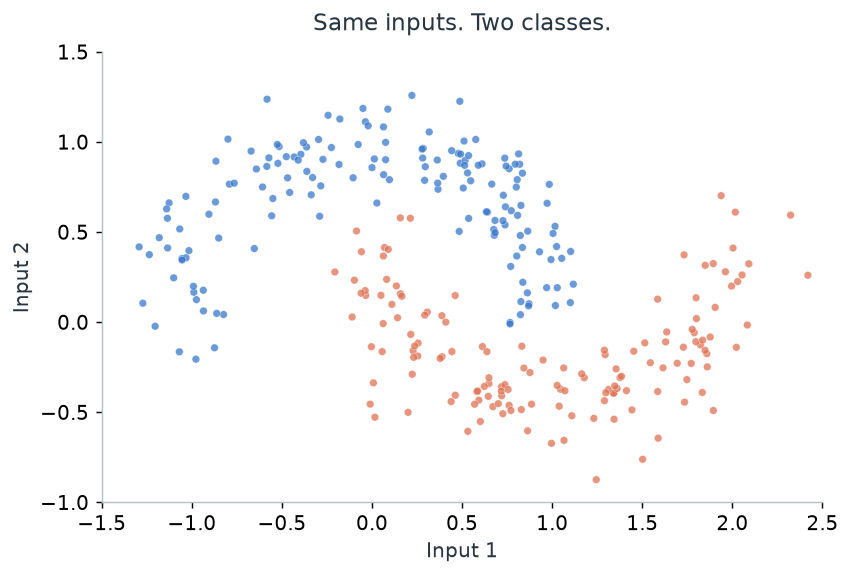

In [17]:
X, y = make_moons(n_samples=1000, noise=.15, random_state=42)
moon_train, moon_val = train_test_split(np.arange(len(y)), test_size=.3, random_state=42)
x_train, x_val, y_train, y_val = X[moon_train], X[moon_val], y[moon_train], y[moon_val]
linear = LogisticRegression(random_state=42).fit(x_train, y_train)
torch.manual_seed(42)
representation_net = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2), nn.Tanh(), nn.Linear(2, 1))
representation_net, snapshots = fit_binary(representation_net, x_train, y_train, snapshots=[0, 10, 50, 100, 300, 600])
gx, gy = np.meshgrid(np.linspace(-1.5, 2.5, 180), np.linspace(-1, 1.5, 140))
moon_grid = np.c_[gx.ravel(), gy.ravel()]


def moon_panel(ax, title, scores=None):
    if scores is not None:
        surface = np.asarray(scores).reshape(gx.shape)
        ax.contourf(gx, gy, surface > 0, levels=[-.5, .5, 1.5], colors=CLASS_COLORS, alpha=.10)
        if surface.min() < 0 < surface.max():
            ax.contour(gx, gy, surface, levels=[0], colors=INK, linewidths=1.5)
    ax.scatter(*x_val.T, c=y_val, cmap=ListedColormap(CLASS_COLORS), s=18, alpha=.75, edgecolor='white', linewidth=.25)
    ax.set(xlim=(-1.5, 2.5), ylim=(-1, 1.5), xlabel='Input 1', ylabel='Input 2', title=title)
    ax.set_aspect('equal')


fig_question, ax = plt.subplots(figsize=(9, 4.5))
moon_panel(ax, 'Same inputs. Two classes.')
fig_answer, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
linear_accuracy = linear.score(x_val, y_val)
neural_accuracy = ((values(representation_net, x_val).ravel() > 0) == y_val).mean()
for ax, title, scores, predictions in [
    (axes[0], f'Logistic regression · validation {linear_accuracy:.1%}', linear.decision_function(moon_grid), linear.predict(x_val)),
    (axes[1], f'Neural network · validation {neural_accuracy:.1%}', values(representation_net, moon_grid), values(representation_net, x_val).ravel() > 0)]:
    moon_panel(ax, title, scores)
    wrong = predictions != y_val
    ax.scatter(*x_val[wrong].T, s=42, facecolors='none', edgecolors=INK, linewidth=.9, label='Mistake')
    ax.legend(loc='upper right', fontsize=9)
figure_switch([('Before fitting', fig_question), ('Compare fitted boundaries', fig_answer)])

## 2. Learn Coordinates Where a Line Works

The last hidden layer has just two units, so we can see its representation directly—this is not PCA or t-SNE. The points on the right are the **same held-out observations**, transformed by the network. Its final layer still draws a straight boundary. What changes during training is the space in which that line is drawn.

The architecture is $2 \rightarrow 16 \rightarrow 2 \rightarrow 1$: ReLU after the first hidden layer, tanh after the second, and one output logit. Unlike PCA, these coordinates are learned using the class labels.

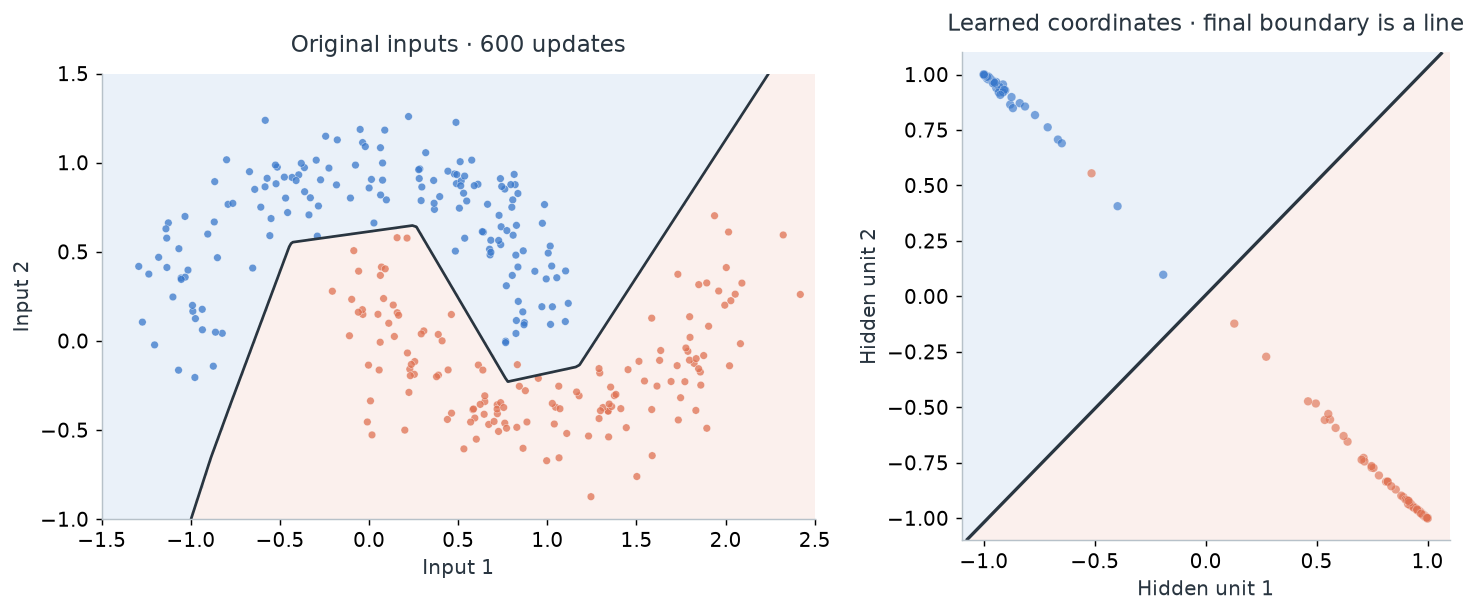

In [18]:
representation_views = []
for step, model in snapshots.items():
    hidden = values(model[:-1], x_val)
    weight = model[-1].weight.detach().numpy()[0]
    bias = model[-1].bias.item()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
    moon_panel(axes[0], f'Original inputs · {step} updates', values(model, moon_grid))
    hx, hy = np.meshgrid(np.linspace(-1.1, 1.1, 120), np.linspace(-1.1, 1.1, 120))
    logits = weight[0] * hx + weight[1] * hy + bias
    axes[1].contourf(hx, hy, logits > 0, levels=[-.5, .5, 1.5], colors=CLASS_COLORS, alpha=.10)
    if logits.min() < 0 < logits.max():
        axes[1].contour(hx, hy, logits, levels=[0], colors=INK, linewidths=1.8)
    axes[1].scatter(*hidden.T, c=y_val, cmap=ListedColormap(CLASS_COLORS), s=23, alpha=.65, edgecolor='white', linewidth=.2)
    axes[1].set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), xlabel='Hidden unit 1', ylabel='Hidden unit 2',
                title='Learned coordinates · final boundary is a line', aspect='equal')
    representation_views.append((f'{step} updates', fig))
figure_switch(representation_views, 'Training', initial=len(representation_views) - 1)

### Why Put an Activation Between Layers?

Without a nonlinear activation, two affine layers collapse into one: $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$. Depth alone would not bend our boundary.

The activation also controls how gradients pass backward. Sigmoid and tanh have small slopes in their saturated regions. ReLU has slope one on its positive side and zero on its negative side; that helps in some situations, but it does not guarantee healthy gradients through an entire network.

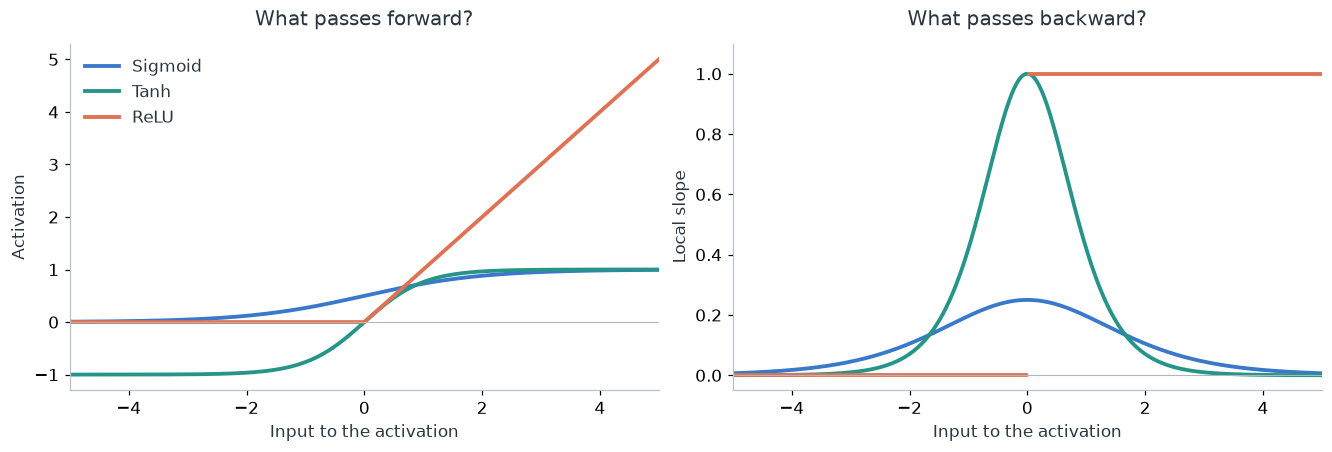

In [19]:
z = np.linspace(-5, 5, 501)
sigmoid = 1 / (1 + np.exp(-z))
activations = [('Sigmoid', BLUE, sigmoid, sigmoid * (1 - sigmoid)),
               ('Tanh', TEAL, np.tanh(z), 1 - np.tanh(z)**2),
               ('ReLU', CORAL, np.maximum(z, 0), np.where(z == 0, np.nan, (z > 0).astype(float)))]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for name, color, activation, slope in activations:
    axes[0].plot(z, activation, color=color, lw=2.5, label=name)
    axes[1].plot(z, slope, color=color, lw=2.5)
for ax in axes:
    ax.axhline(0, color='#ADB7C0', lw=.7)
    ax.set(xlabel='Input to the activation', xlim=(-5, 5))
axes[0].set(title='What passes forward?', ylabel='Activation')
axes[1].set(title='What passes backward?', ylabel='Local slope', ylim=(-.05, 1.1))
axes[0].legend(frameon=False)
plt.show()

### What Does More Width Buy Us?

How does the fitted boundary change when we give a network more hidden units? We keep one ReLU hidden layer and the same 700 training observations. Each width gets 10,000 Adam updates at learning rate 0.01, with no dropout or weight decay, for three random initializations.

The panels show seed 42 and the same 300 validation points as before. Their scores compare the 700 training observations with a separate set of 10,000 held-out observations from the same synthetic distribution. Those extra observations never enter the training updates; they give us a less coarse view than counting mistakes on 300 points. This is an exploratory comparison, not a final test estimate.

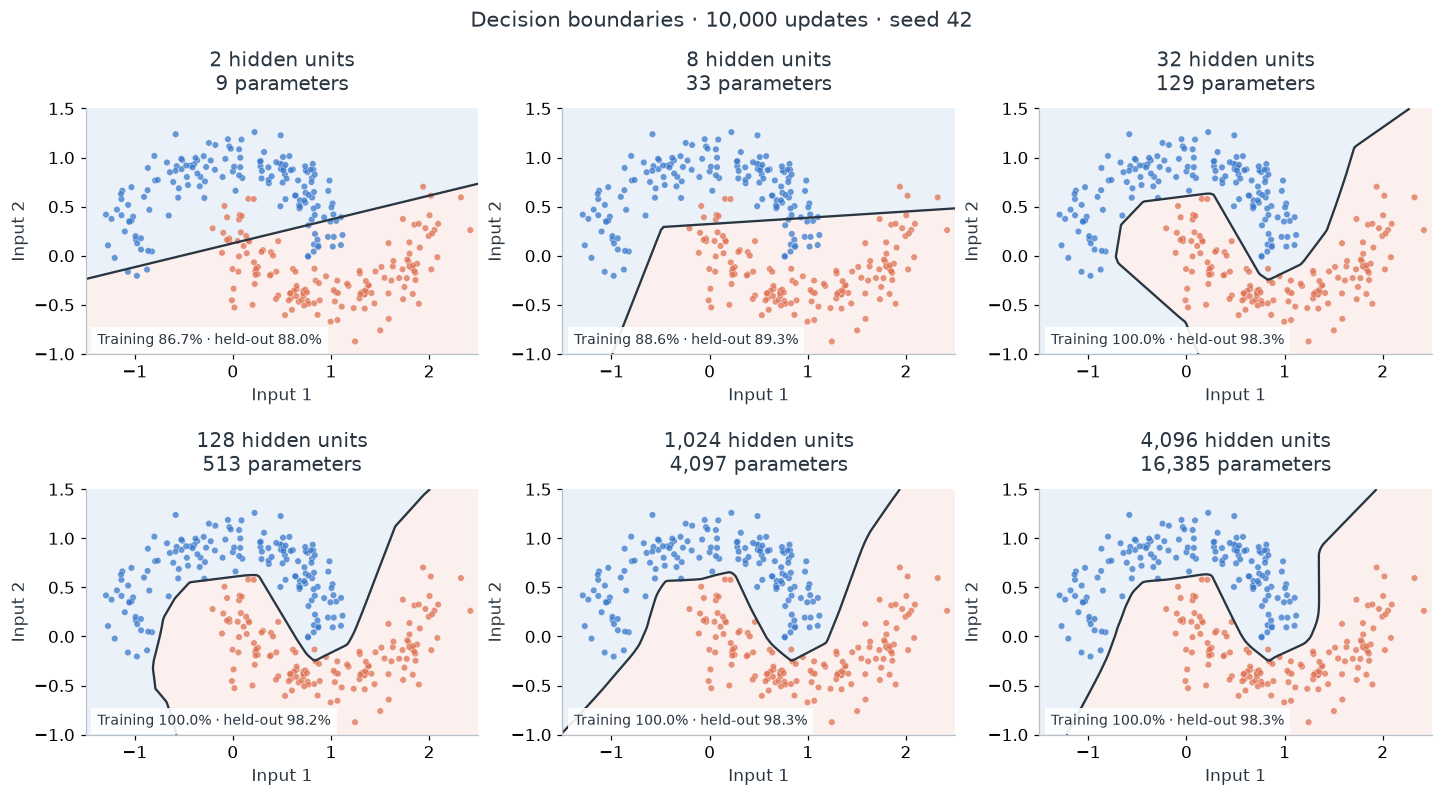

In [20]:
widths, seeds, width_steps = [2, 8, 32, 128, 1024, 4096], [0, 1, 42], 10000
width_x, width_y = make_moons(n_samples=10000, noise=.15, random_state=20261019)
width_runs = {}
# This sweep trains 18 models and takes a few minutes on CPU.
for width in widths:
    for seed in seeds:
        torch.manual_seed(seed)
        model, _ = fit_binary(mlp([2, width, 1]), x_train, y_train, steps=width_steps)
        scores = []
        for inputs, labels in [(x_train, y_train), (width_x, width_y)]:
            logits = torch.from_numpy(values(model, inputs)).ravel()
            targets = torch.as_tensor(labels, dtype=torch.float32)
            accuracy = ((logits > 0) == targets).float().mean().item()
            cross_entropy = nn.functional.binary_cross_entropy_with_logits(logits, targets).item()
            scores.append([accuracy, cross_entropy])
        width_runs[width, seed] = (model, np.array(scores))
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), layout='constrained')
for ax, width in zip(axes.flat, widths):
    model, scores = width_runs[width, 42]
    parameter_count = sum(p.numel() for p in model.parameters())
    moon_panel(ax, f'{width:,} hidden units\n{parameter_count:,} parameters', values(model, moon_grid))
    ax.text(.03, .04, f'Training {scores[0, 0]:.1%} · held-out {scores[1, 0]:.1%}',
            transform=ax.transAxes, fontsize=9, bbox=dict(facecolor='white', edgecolor='none', alpha=.9))
fig.suptitle(f'Decision boundaries · {width_steps:,} updates · seed 42', fontsize=14)
plt.show()

Accuracy counts correct labels; cross-entropy also measures the probabilities assigned to them. What do the two measures tell us about the same fitted models? The curves below show means across three initializations; the shaded ranges show the lowest and highest values, not confidence intervals.

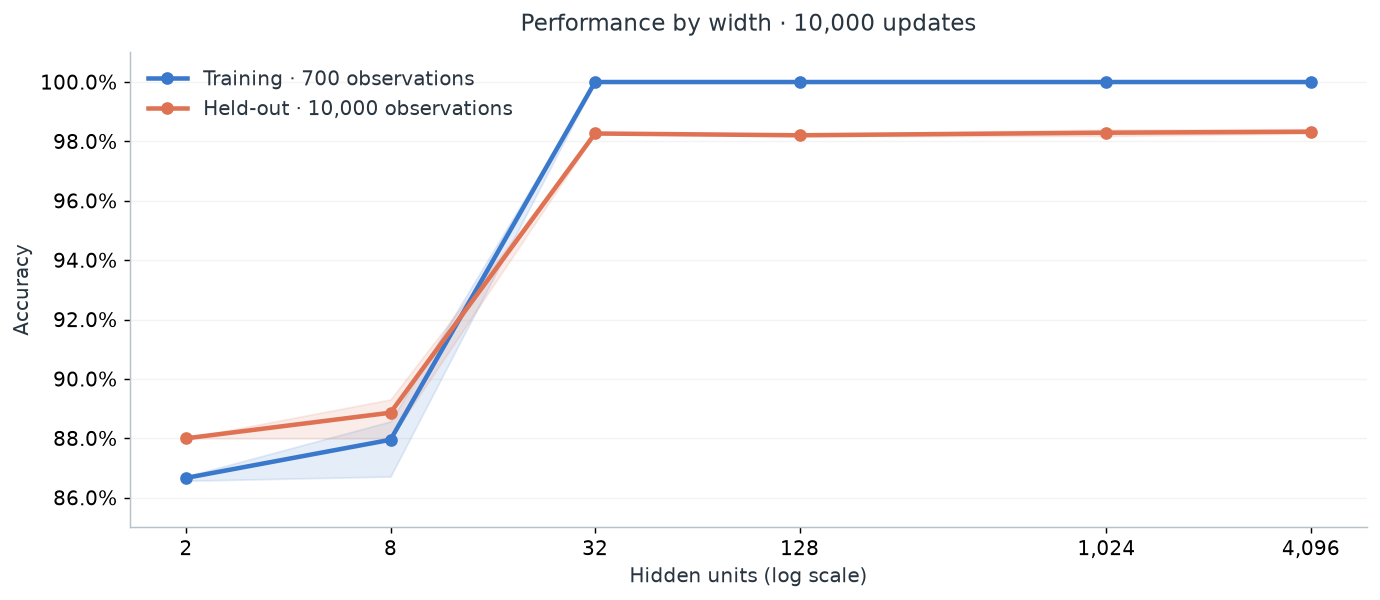

In [21]:
width_scores = np.array([[width_runs[width, seed][1] for seed in seeds] for width in widths])
width_metric_views = []
for metric, name in enumerate(['Accuracy', 'Cross-entropy']):
    fig, ax = plt.subplots(figsize=(10.5, 4.5), layout='constrained')
    for split, label, color in [(0, 'Training · 700 observations', BLUE),
                                (1, 'Held-out · 10,000 observations', CORAL)]:
        scores = width_scores[:, :, split, metric]
        ax.plot(widths, scores.mean(1), 'o-', color=color, lw=2.5, label=label)
        ax.fill_between(widths, scores.min(1), scores.max(1), color=color, alpha=.13)
    ax.set(xscale='log', xticks=widths, xticklabels=[f'{width:,}' for width in widths],
           xlabel='Hidden units (log scale)', ylabel=name,
           title=f'Performance by width · {width_steps:,} updates')
    ax.minorticks_off()
    ax.grid(axis='y', alpha=.15)
    ax.legend(frameon=False, loc='best')
    if metric == 0:
        ax.set_ylim(.85, 1.01)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    else:
        ax.set_ylim(bottom=0)
    width_metric_views.append((name, fig))
figure_switch(width_metric_views, 'Metric')

With enough hidden units, a network with a suitable activation can approximate any continuous function on a compact domain as closely as we want. That is an expressiveness result—the universal approximation theorem—not a promise that training will find those weights or that they will work on unseen data.

## 3. One Prediction, One Backward Pass, One Update

Let's shrink the network to two inputs, two hidden ReLU units, and one output. We will use the **same weights and the same example** throughout. For a target of 1, the initial prediction is too low. Which weights can change that prediction?

PyTorch stores a linear layer's weight matrix as `(outputs, inputs)`, so a batch moves forward as `x @ W.T + b`. The output below is a logit; `binary_cross_entropy_with_logits` combines the sigmoid and cross-entropy calculation stably.

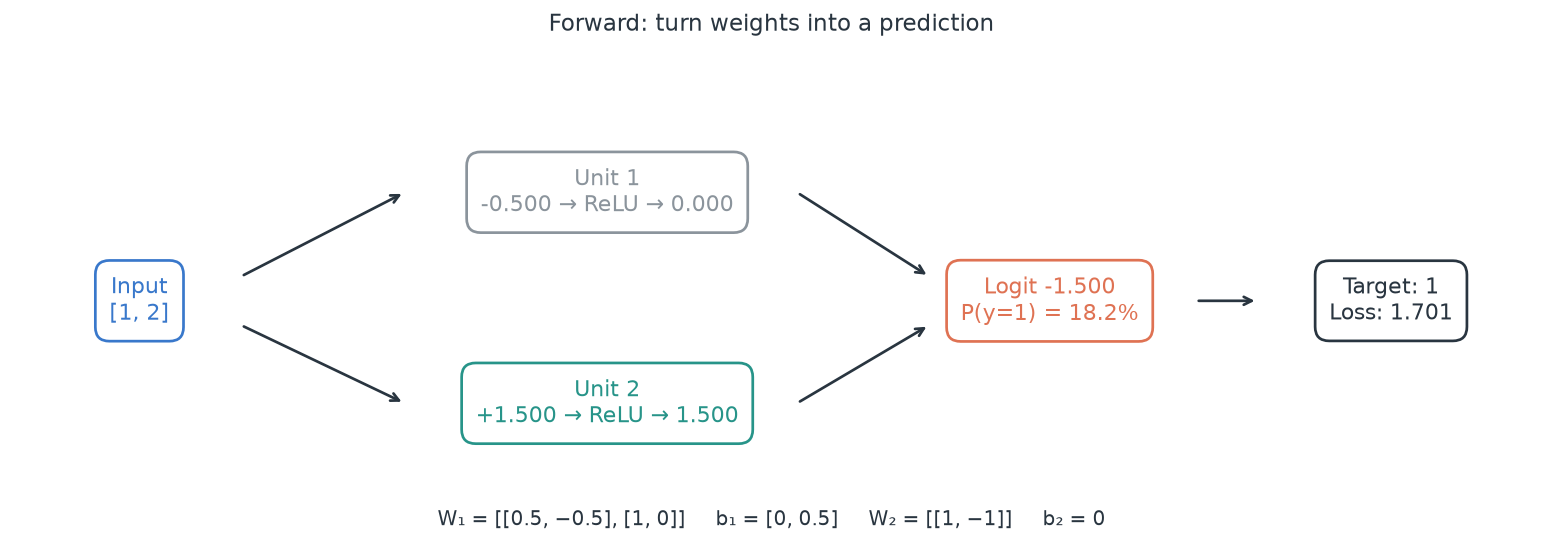

In [22]:
tiny = nn.Sequential(nn.Linear(2, 2), nn.ReLU(), nn.Linear(2, 1)).double()
with torch.no_grad():
    tiny[0].weight.copy_(torch.tensor([[.5, -.5], [1., 0.]], dtype=torch.float64))
    tiny[0].bias.copy_(torch.tensor([0., .5], dtype=torch.float64))
    tiny[2].weight.copy_(torch.tensor([[1., -1.]], dtype=torch.float64))
    tiny[2].bias.zero_()
example = torch.tensor([[1., 2.]], dtype=torch.float64)
target = torch.ones((1, 1), dtype=torch.float64)
optimizer = torch.optim.SGD(tiny.parameters(), lr=.1)
before = copy.deepcopy(tiny)
logit = tiny(example)
loss = nn.functional.binary_cross_entropy_with_logits(logit, target)
optimizer.zero_grad()
loss.backward()
tiny_gradients = [parameter.grad.clone() for parameter in tiny.parameters()]
loss_before, probability_before = loss.item(), logit.sigmoid().item()
optimizer.step()
loss_after = nn.functional.binary_cross_entropy_with_logits(tiny(example), target).item()
probability_after = tiny(example).sigmoid().item()


def tiny_picture(model, stage):
    with torch.no_grad():
        pre = model[0](example).ravel().numpy()
        hidden = np.maximum(pre, 0)
        output = model(example).item()
        probability = torch.sigmoid(torch.tensor(output)).item()
        objective = nn.functional.binary_cross_entropy_with_logits(model(example), target).item()
    fig, ax = plt.subplots(figsize=(12, 4.4))
    ax.set(xlim=(0, 12), ylim=(0, 4)); ax.axis('off')
    hidden_labels = [f'Unit {i+1}\n{pre[i]:+.3f} → ReLU → {hidden[i]:.3f}' for i in range(2)]
    output_label = f'Logit {output:+.3f}\nP(y=1) = {probability:.1%}'
    if stage == 'backward':
        hidden_labels = ['Unit 1 · inactive\n∂loss/∂z₁ = 0', f'Unit 2 · active\n∂loss/∂z₂ = {1 - probability_before:+.3f}']
        output_label = f'∂loss/∂logit\n= p − y = {probability_before - 1:+.3f}'
    boxes = [(1, 2, 'Input\n[1, 2]', BLUE),
             (4.7, 2.9, hidden_labels[0], '#8B949C'),
             (4.7, 1.15, hidden_labels[1], TEAL),
             (8.2, 2, output_label, CORAL),
             (10.9, 2, f'Target: 1\nLoss: {objective:.3f}', INK)]
    for x0, y0, label, color in boxes:
        ax.text(x0, y0, label, ha='center', va='center', fontsize=12, color=color,
                bbox=dict(boxstyle='round,pad=.65', fc='white', ec=color, lw=1.5))
    for start, end in [((1.8, 2.2), (3.1, 2.9)), ((1.8, 1.8), (3.1, 1.15)),
                       ((6.2, 2.9), (7.25, 2.2)), ((6.2, 1.15), (7.25, 1.8)), ((9.35, 2), (9.85, 2))]:
        if stage == 'backward':
            start, end = end, start
        ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=CORAL if stage == 'backward' else INK, lw=1.5))
    if stage == 'backward':
        message = (f'Unit 2 incoming gradients: {1 - probability_before:.3f} × [1, 2] = '
                   f'[{tiny_gradients[0][1,0]:.3f}, {tiny_gradients[0][1,1]:.3f}]\n'
                   'Unit 1 is inactive on this example: its incoming weight gradients are zero.')
    elif stage == 'update':
        message = f'W₁[1,0]: 1.000 − 0.1 × {tiny_gradients[0][1,0]:.3f} = {model[0].weight[1,0].item():.3f}     |     All parameters get their own update.'
    else:
        message = 'W₁ = [[0.5, −0.5], [1, 0]]     b₁ = [0, 0.5]     W₂ = [[1, −1]]     b₂ = 0'
    ax.text(6, .1, message, ha='center', va='bottom', fontsize=11)
    ax.set_title({'forward': 'Forward: turn weights into a prediction', 'backward': 'Backward: assign a local sensitivity to each parameter',
                  'update': 'Update: move the parameters, then predict again'}[stage], pad=16)
    fig.tight_layout()
    return fig


figure_switch([('Forward pass', tiny_picture(before, 'forward')),
               ('Reveal gradients', tiny_picture(before, 'backward')),
               ('After one update', tiny_picture(tiny, 'update'))], 'Step')

A gradient is a local sensitivity, not the new weight. We subtract a small multiple of it to reduce the loss. Here the inactive ReLU blocks the gradient for this example; it need not be inactive on every example.

We can check one derivative without backpropagation: nudge the active unit's first weight up and down, then measure the change in loss. In Python's zero-based indexing, this is `W₁[1,0]`: input 1 to hidden unit 2. We use double precision and stay away from ReLU's kink at zero.

In [23]:
checked = copy.deepcopy(before)
checked.zero_grad()
nn.functional.binary_cross_entropy_with_logits(checked(example), target).backward()
analytic = checked[0].weight.grad[1, 0].item()
epsilon = 1e-5
with torch.no_grad():
    original = checked[0].weight[1, 0].item()
    checked[0].weight[1, 0] = original + epsilon
    plus = nn.functional.binary_cross_entropy_with_logits(checked(example), target).item()
    checked[0].weight[1, 0] = original - epsilon
    minus = nn.functional.binary_cross_entropy_with_logits(checked(example), target).item()
    checked[0].weight[1, 0] = original
numerical = (plus - minus) / (2 * epsilon)
print(f'Autograd: {analytic:.8f} · finite difference: {numerical:.8f} · difference: {abs(analytic - numerical):.2e}')
print(f'One update: loss {loss_before:.3f} → {loss_after:.3f}; P(y=1) {probability_before:.1%} → {probability_after:.1%}')

Autograd: 0.81757448 · finite difference: 0.81757448 · difference: 3.70e-12
One update: loss 1.701 → 1.174; P(y=1) 18.2% → 30.9%


## 4. Can the Signal Survive the Journey?

Even before training, weight scale can make a deep network difficult to optimize. These 12-layer ReLU networks see the same synthetic inputs and random targets. Each layer uses the same underlying random matrix across conditions; only its scale changes. Every hidden bias starts at zero.

The left panel follows activation size forward. The right follows weight-gradient size through those same layers after one backward pass. He scaling uses a variance of $2/\text{fan-in}$ to compensate for the signal lost through ReLU. This is an initialization diagnostic, not an accuracy comparison.

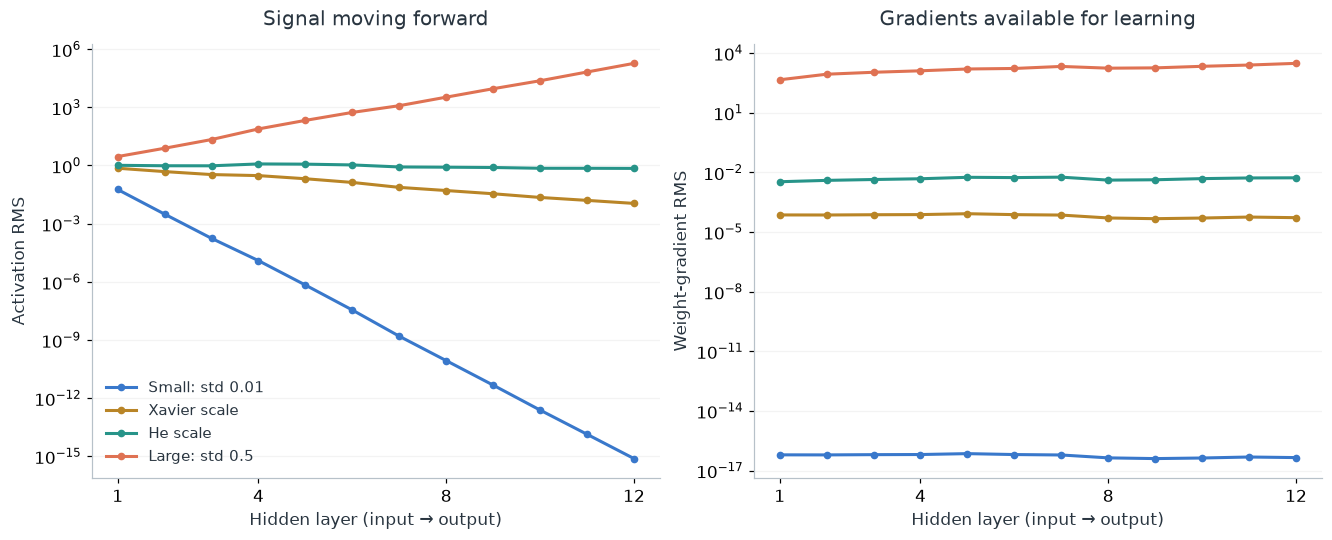

Zero initialization: 0/12 hidden layers have nonzero activations; 0/12 have nonzero weight gradients.


In [24]:
torch.manual_seed(42)
probe_inputs = torch.randn(512, 64)
probe_targets = torch.randint(10, (512,))
base_weights = [torch.randn(64, 64) for _ in range(12)]
readout = torch.randn(10, 64) / np.sqrt(64)
scales = [('Small: std 0.01', .01, BLUE), ('Xavier scale', 1 / np.sqrt(64), GOLD),
          ('He scale', np.sqrt(2 / 64), TEAL), ('Large: std 0.5', .5, CORAL)]
init_results = {}
for name, scale, color in scales + [('All hidden weights zero', 0., INK)]:
    net = mlp([64] * 13 + [10])
    linears = [layer for layer in net if isinstance(layer, nn.Linear)]
    with torch.no_grad():
        for layer, base in zip(linears[:-1], base_weights):
            layer.weight.copy_(base * scale); layer.bias.zero_()
        linears[-1].weight.copy_(readout); linears[-1].bias.zero_()
    h, magnitudes = probe_inputs, []
    for layer in net:
        h = layer(h)
        if isinstance(layer, nn.ReLU):
            magnitudes.append(h.square().mean().sqrt().item())
    nn.functional.cross_entropy(h, probe_targets).backward()
    gradients = [layer.weight.grad.square().mean().sqrt().item() for layer in linears[:-1]]
    init_results[name] = (np.array(magnitudes), np.array(gradients))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for name, scale, color in scales:
    for ax, measurement in zip(axes, init_results[name]):
        ax.plot(np.arange(1, 13), measurement, 'o-', color=color, lw=2, ms=4, label=name)
for ax in axes:
    ax.set(yscale='log', xlabel='Hidden layer (input → output)', xticks=[1, 4, 8, 12])
    ax.grid(axis='y', alpha=.15)
axes[0].set(title='Signal moving forward', ylabel='Activation RMS')
axes[1].set(title='Gradients available for learning', ylabel='Weight-gradient RMS')
axes[0].legend(frameon=False, fontsize=10)
plt.show()
zero_activations, zero_gradients = init_results['All hidden weights zero']
print(f'Zero initialization: {np.count_nonzero(zero_activations)}/12 hidden layers have nonzero activations; '
      f'{np.count_nonzero(zero_gradients)}/12 have nonzero weight gradients.')

## 5. From Two Inputs to 3,072 Pixels

[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) contains 32 × 32 color photographs in ten categories. We'll reserve 5,000 of the 50,000 training images for validation and leave the official 10,000-image test set aside until the end.

Flattening preserves every pixel value, but a fully connected layer does not build in the idea that nearby pixels belong together. Let's see how far it gets. The images below are actual training examples, one per class.

Files already downloaded and verified
Files already downloaded and verified


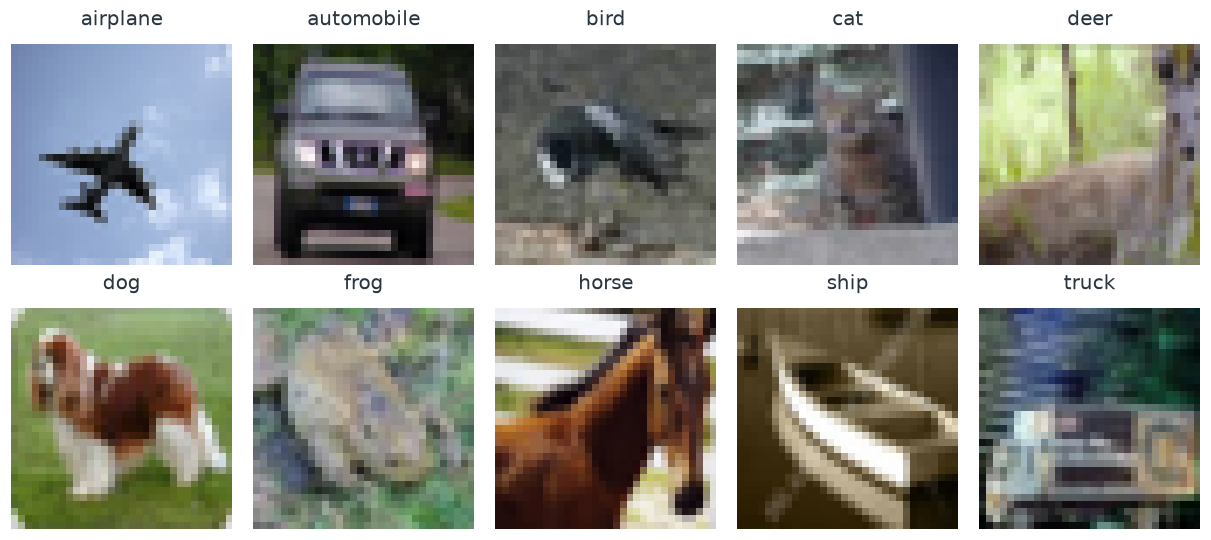

Training: 45,000 · validation: 5,000 · untouched test: 10,000


In [25]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,) * 3, (.5,) * 3)])
cifar = datasets.CIFAR10(root='data', train=True, download=True, transform=transform)
cifar_test = datasets.CIFAR10(root='data', train=False, download=True, transform=transform)
train_ids, val_ids = train_test_split(np.arange(len(cifar)), test_size=5000,
                                     stratify=cifar.targets, random_state=42)
classes = cifar.classes
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8), layout='constrained')
for label, ax in enumerate(axes.flat):
    index = train_ids[np.flatnonzero(np.array(cifar.targets)[train_ids] == label)[0]]
    ax.imshow(cifar.data[index]); ax.set_title(classes[label]); ax.axis('off')
plt.show()
print(f'Training: {len(train_ids):,} · validation: {len(val_ids):,} · untouched test: {len(cifar_test):,}')

Our MLP is $3072 \rightarrow 512 \rightarrow 256 \rightarrow 128 \rightarrow 10$. The hidden layers use ReLU and dropout; the output is ten logits. Cross-entropy compares them with the correct class.

The training loop has the same three operations as our tiny example: compute the loss, call `backward()`, and take an optimizer `step()`. Dropout randomly removes hidden activations during training and rescales the survivors; in evaluation mode it is the identity. We measure both training and validation curves in evaluation mode so they are comparable.

In [26]:
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
generator = torch.Generator().manual_seed(42)
train_loader = DataLoader(Subset(cifar, train_ids), batch_size=128, shuffle=True, generator=generator)
train_eval_loader = DataLoader(Subset(cifar, train_ids), batch_size=512)
val_loader = DataLoader(Subset(cifar, val_ids), batch_size=512)
test_loader = DataLoader(cifar_test, batch_size=512)
image_net = nn.Sequential(nn.Flatten(), mlp([3072, 512, 256, 128, 10], dropout=.2)).to(device)
optimizer = torch.optim.Adam(image_net.parameters(), lr=.001)


@torch.no_grad()
def evaluate(model, loader, keep_predictions=False):
    model.eval()
    total_loss, correct, count, predictions = 0., 0, 0, []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += nn.functional.cross_entropy(logits, labels, reduction='sum').item()
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
        if keep_predictions:
            predictions.append(logits.softmax(1).cpu().numpy())
    return total_loss / count, correct / count, np.concatenate(predictions) if predictions else None


history = []
train_loss, train_accuracy, _ = evaluate(image_net, train_eval_loader)
val_loss, val_accuracy, _ = evaluate(image_net, val_loader)
history.append([0, train_loss, val_loss, train_accuracy, val_accuracy])
training_objectives = []
with torch.enable_grad():
    for epoch in range(1, 6):
        image_net.train()
        total_loss, count = 0., 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            loss = nn.functional.cross_entropy(image_net(images), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
            count += len(labels)
        training_objectives.append(total_loss / count)
        train_loss, train_accuracy, _ = evaluate(image_net, train_eval_loader)
        val_loss, val_accuracy, _ = evaluate(image_net, val_loader)
        history.append([epoch, train_loss, val_loss, train_accuracy, val_accuracy])
        print(f'Epoch {epoch}/5 · training accuracy {train_accuracy:.1%} · validation accuracy {val_accuracy:.1%} · validation loss {val_loss:.3f}')
history = np.array(history)
parameters = sum(p.numel() for p in image_net.parameters())
first_layer_parameters = sum(p.numel() for p in image_net[1][0].parameters())
print(f'{parameters:,} parameters · {first_layer_parameters / parameters:.1%} in the first layer · device: {device}')

Epoch 1/5 · training accuracy 46.2% · validation accuracy 44.2% · validation loss 1.558
Epoch 2/5 · training accuracy 50.1% · validation accuracy 47.5% · validation loss 1.480
Epoch 3/5 · training accuracy 53.0% · validation accuracy 48.5% · validation loss 1.451
Epoch 4/5 · training accuracy 55.8% · validation accuracy 50.5% · validation loss 1.400
Epoch 5/5 · training accuracy 57.4% · validation accuracy 51.1% · validation loss 1.376
1,738,890 parameters · 90.5% in the first layer · device: cpu


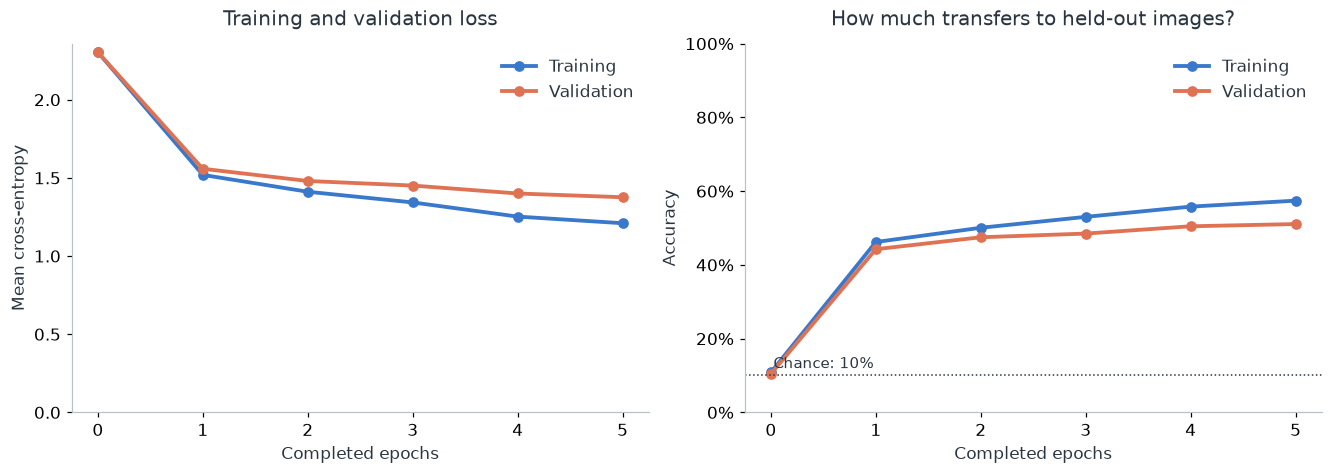

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for ax, columns in zip(axes, [(1, 2), (3, 4)]):
    for column, name, color in zip(columns, ['Training', 'Validation'], [BLUE, CORAL]):
        ax.plot(history[:, 0], history[:, column], 'o-', lw=2.5, color=color, label=name)
    ax.set(xlabel='Completed epochs', xticks=np.arange(6))
    ax.legend(frameon=False)
axes[0].set(title='Training and validation loss', ylabel='Mean cross-entropy', ylim=(0, None))
axes[1].set(title='How much transfers to held-out images?', ylabel='Accuracy', ylim=(0, 1))
axes[1].axhline(.1, color=INK, ls=':', lw=1)
axes[1].text(.05, .12, 'Chance: 10%', transform=axes[1].transAxes, fontsize=10)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 6. What Has the Network Actually Learned?

After five epochs, we evaluate once on the untouched test set. Overall accuracy is only the beginning: which classes work well, and what do confident mistakes look like? The examples are deliberately selected from the test predictions to make those cases visible; they are not a representative sample of all mistakes. A model probability is not a guarantee of correctness or calibration.

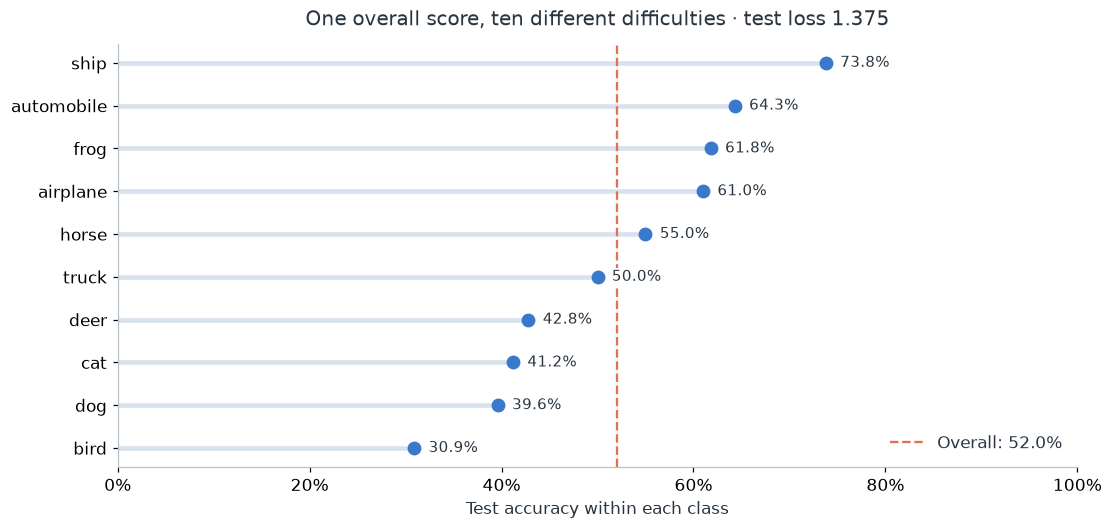

In [28]:
test_loss, test_accuracy, test_probabilities = evaluate(image_net, test_loader, keep_predictions=True)
test_labels = np.array(cifar_test.targets)
test_predictions = test_probabilities.argmax(1)
class_accuracy = np.array([(test_predictions[test_labels == label] == label).mean() for label in range(10)])
order = np.argsort(class_accuracy)
fig, ax = plt.subplots(figsize=(10, 4.7), layout='constrained')
ax.hlines(np.arange(10), 0, class_accuracy[order], color='#D8E2EE', lw=3)
ax.scatter(class_accuracy[order], np.arange(10), s=65, color=BLUE, zorder=3)
for row, accuracy in enumerate(class_accuracy[order]):
    ax.text(accuracy + .015, row, f'{accuracy:.1%}', va='center', fontsize=10,
            bbox=dict(facecolor='white', edgecolor='none', pad=.5))
ax.axvline(test_accuracy, color=CORAL, ls='--', lw=1.5, label=f'Overall: {test_accuracy:.1%}')
ax.set(yticks=np.arange(10), yticklabels=np.array(classes)[order], xlim=(0, 1),
       xlabel='Test accuracy within each class', title=f'One overall score, ten different difficulties · test loss {test_loss:.3f}')
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(loc='lower right', frameon=False)
plt.show()

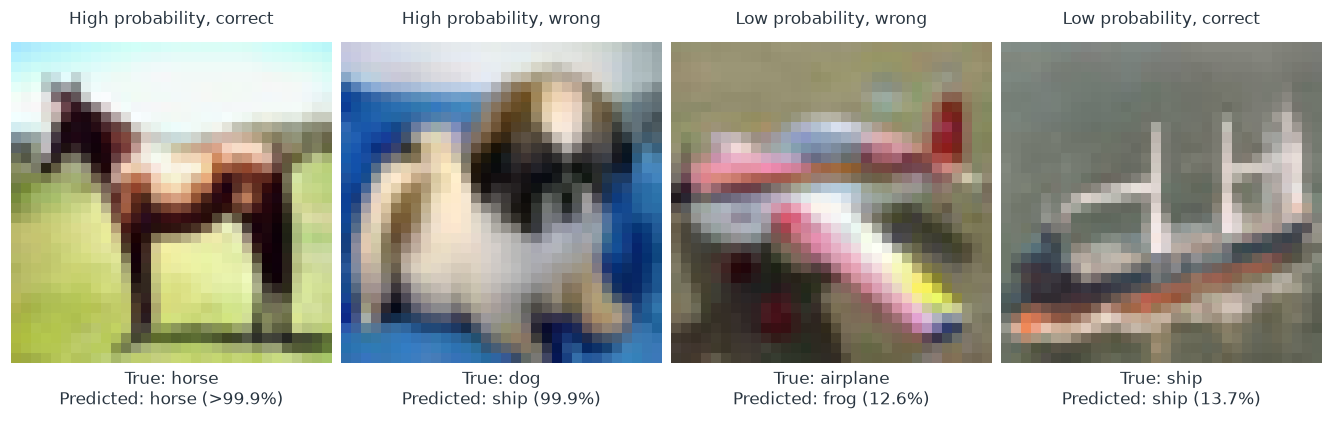

In [29]:
confidence = test_probabilities.max(1)
correct_mask = test_predictions == test_labels
correct_ids, wrong_ids = np.flatnonzero(correct_mask), np.flatnonzero(~correct_mask)
case_ids = [correct_ids[np.argmax(confidence[correct_ids])], wrong_ids[np.argmax(confidence[wrong_ids])],
            wrong_ids[np.argmin(confidence[wrong_ids])], correct_ids[np.argmin(confidence[correct_ids])]]
case_names = ['High probability, correct', 'High probability, wrong', 'Low probability, wrong', 'Low probability, correct']
fig, axes = plt.subplots(1, 4, figsize=(12, 4), layout='constrained')
for ax, index, name in zip(axes, case_ids, case_names):
    ax.imshow(cifar_test.data[index]); ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(name, fontsize=11)
    probability_text = '>99.9%' if confidence[index] > .999 else f'{confidence[index]:.1%}'
    ax.set_xlabel(f'True: {classes[test_labels[index]]}\nPredicted: {classes[test_predictions[index]]} ({probability_text})', fontsize=11)
plt.show()

## What to Take Away

A fully connected network learns features and a predictor together: nonlinear hidden layers can turn a difficult boundary into a simple one in learned coordinates. Backpropagation tells us how each parameter affects the current loss, and the optimizer turns those sensitivities into updates. Activation choice and initialization determine whether useful signals can travel through the network, but none of this guarantees generalization. Our image experiment therefore ends with held-out predictions, including confident mistakes. Flattening has kept the pixels, yet the MLP has no built-in preference for local image structure—the motivation for the convolutional architectures we'll study next.